# Lab 6 – Capstone: Dự báo khách hàng rời bỏ (Churn) – quy trình end-to-end ⭐⭐⭐⭐⭐ (Mức: Nâng cao)

> **Học phần Machine Learning – Chương 3: Supervised Learning**
> PGS.TS. Lê Hoành Sử · Khoa Hệ thống thông tin · Trường ĐH Kinh tế – Luật (UEL)
>
> 💡 *Cách chạy trên Google Colab:* `File → Upload notebook` (hoặc mở từ Google Drive), sau đó `Runtime → Run all`. Dữ liệu được tải trực tiếp từ GitHub nên **không cần upload file dữ liệu**.

## 🎯 Mục tiêu
Đây là bài tổng hợp theo đúng **checklist end-to-end** của chương:
1. **Định nghĩa bài toán kinh doanh** và chi phí sai lầm.
2. **Làm sạch** dữ liệu thật (kiểu dữ liệu sai, chuỗi rỗng).
3. **Pipeline** đầy đủ cho dữ liệu hỗn hợp; benchmark 7 mô hình: Logistic, Naive Bayes, kNN, Random Forest, Gradient Boosting, **SVM (RBF)**, **MLP**.
4. Xử lý **lệch lớp** bằng **dịch chuyển ngưỡng** (threshold moving); đánh giá bằng **ROC-AUC, PR-AUC, F1**.
5. **GridSearchCV** cho mô hình được chọn.
6. **Chọn ngưỡng tối ưu theo lợi nhuận** chiến dịch giữ chân.
7. Giải thích mô hình, **lưu mô hình** (`joblib`) và viết **model card**.

## 📦 Dữ liệu
- Nguồn: `IBM/telco-customer-churn-on-icp4d` → `data/Telco-Customer-Churn.csv` (7.043 khách hàng viễn thông).
- Target: `Churn` (Yes/No) – khách có rời bỏ trong tháng vừa qua.

## 💼 Bối cảnh kinh doanh (giả định để tính toán)
- Mỗi khách giữ chân thành công mang lại **CLV ≈ 500 USD**.
- Chi phí một ưu đãi giữ chân: **50 USD**/khách; tỷ lệ chấp nhận ưu đãi của khách sắp rời: **40%**.
- → Tìm ra khách **sắp rời** (TP) có lợi: 0.4×500 − 50 = **+150 USD**; gửi ưu đãi nhầm cho khách **không rời** (FP): **−50 USD**.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time, joblib, warnings
warnings.filterwarnings("ignore", category=UserWarning)

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
RANDOM_STATE = 42

In [ ]:
# BỔ SUNG KỸ THUẬT — tương thích Seaborn 0.13.2 với Matplotlib 3.10+
# Không thay đổi logic/code gốc của bài; chỉ xử lý lỗi màu mặc định khi sns.barplot() chạy trên môi trường mới.
import seaborn.categorical as _sns_cat
_sns_default_color_original = _sns_cat._default_color

def _sns_default_color_compat(method, hue, color, kws, saturation=1):
    if hue is None and color is None and getattr(method, "__name__", "") == "wrapper":
        color = sns.color_palette()[0]
    return _sns_default_color_original(method, hue, color, kws, saturation=saturation)

_sns_cat._default_color = _sns_default_color_compat

## Bước 1. Tải dữ liệu & kiểm tra chất lượng

> **Hai cách nạp dữ liệu (chọn một):**
> - **Dùng gói `DS6_TelcoChurn.zip`:** upload file zip lên Colab rồi chạy ô bên dưới để giải nén; notebook sẽ đọc file `Telco-Customer-Churn.csv` trong gói.
> - **Đọc trực tiếp từ GitHub:** bỏ qua ô giải nén; nếu không tìm thấy file cục bộ, notebook tự tải dữ liệu từ GitHub.

In [ ]:
# (Tùy chọn) Chỉ chạy trên Colab khi dùng gói dữ liệu: upload DS6_TelcoChurn.zip rồi giải nén
# from google.colab import files
# files.upload()                 # chọn DS6_TelcoChurn.zip
# !unzip -o DS6_TelcoChurn.zip

In [ ]:
import os
URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
# Ưu tiên file CSV trong gói DS6_TelcoChurn.zip (đặt cùng thư mục notebook hoặc đã giải nén trên Colab);
# nếu không tìm thấy file thì tự động tải từ GitHub.
LOCAL_FILES = ["Telco-Customer-Churn.csv", "DS6_TelcoChurn/Telco-Customer-Churn.csv", "/content/DS6_TelcoChurn/Telco-Customer-Churn.csv"]
local = next((p for p in LOCAL_FILES if os.path.exists(p)), None)
df = pd.read_csv(local) if local else pd.read_csv(URL)
print("Nguồn dữ liệu:", local or URL)
print(df.shape)
print(df.dtypes.value_counts())
df.head(3)

Nguồn dữ liệu: Telco-Customer-Churn.csv
(7043, 21)
object     18
int64       2
float64     1
Name: count, dtype: int64


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


⚠️ `TotalCharges` là số nhưng bị đọc thành **chuỗi** → có giá trị lạ. Kiểm tra:

In [ ]:
print("Kiểu TotalCharges:", df["TotalCharges"].dtype)
bad = pd.to_numeric(df["TotalCharges"], errors="coerce").isna()
print("Số dòng không chuyển được sang số:", bad.sum())
df.loc[bad, ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

Kiểu TotalCharges: object
Số dòng không chuyển được sang số: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


Các dòng này đều có `tenure = 0` (khách mới, chưa có hóa đơn) → chuỗi rỗng. Ta chuyển thành NaN và để `SimpleImputer` xử lý trong Pipeline.

In [ ]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["Churn"] = (df["Churn"] == "Yes").astype(int)
df = df.drop(columns="customerID")          # ID không mang thông tin dự báo
print("Tỷ lệ churn:", round(df["Churn"].mean(), 3))

Tỷ lệ churn: 0.265


## Bước 2. EDA hướng nghiệp vụ

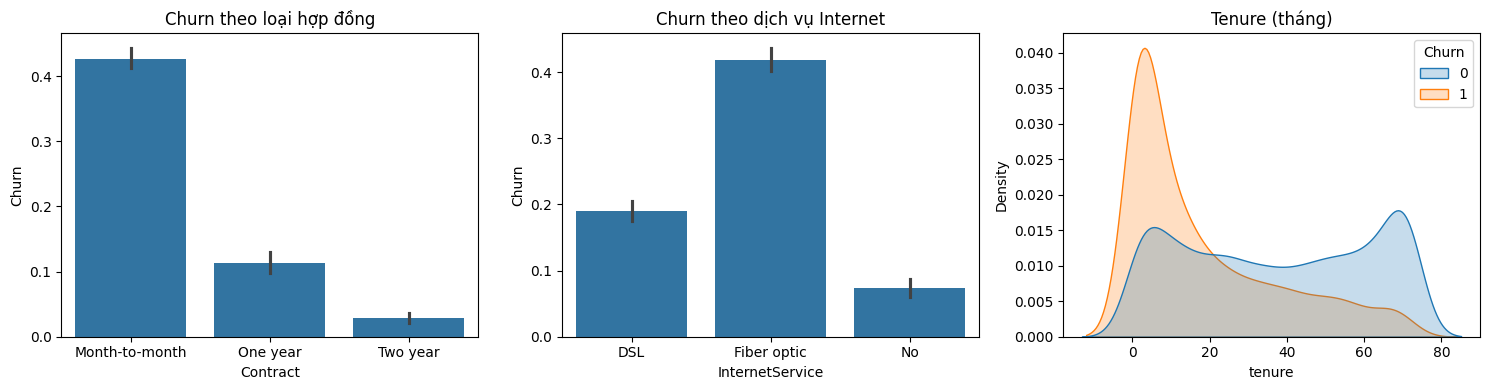

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.barplot(data=df, x="Contract", y="Churn", ax=ax[0]); ax[0].set_title("Churn theo loại hợp đồng")
sns.barplot(data=df, x="InternetService", y="Churn", ax=ax[1]); ax[1].set_title("Churn theo dịch vụ Internet")
sns.kdeplot(data=df, x="tenure", hue="Churn", common_norm=False, fill=True, ax=ax[2]); ax[2].set_title("Tenure (tháng)")
plt.tight_layout(); plt.show()

**🔎 Insight:** khách **hợp đồng theo tháng**, dùng **Fiber optic**, **tenure thấp** có tỷ lệ churn cao nhất. Dữ liệu **lệch lớp** (~26.5% churn) → accuracy không phải thước đo chính.

## Bước 3. Chia dữ liệu & Pipeline tiền xử lý

In [ ]:
X = df.drop(columns="Churn")
y = df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

num_cols = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
cat_cols = [c for c in X.columns if c not in num_cols]
print("Numeric:", num_cols); print("Categorical:", len(cat_cols), "cột")

preprocess = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])

Numeric: ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']
Categorical: 15 cột


## Bước 4. Benchmark 7 mô hình bằng 5-fold Stratified CV
- Có 2 cách xử lý lệch lớp: (a) `class_weight="balanced"` khi huấn luyện, (b) giữ xác suất "thật" rồi **dịch chuyển ngưỡng** theo chi phí kinh doanh. Lab này dùng cách (b) vì xác suất không bị méo – rất quan trọng khi tính lợi nhuận ở Bước 7. (Cách (a) để dành cho bài tập.)
- Thước đo: **ROC-AUC** (xếp hạng), **PR-AUC** (tập trung vào lớp dương, phù hợp khi lệch lớp), **F1**.

In [ ]:
def make(model):
    return Pipeline([("prep", preprocess), ("model", model)])

bench = {
    "LogisticRegression": make(LogisticRegression(max_iter=2000)),
    "GaussianNB":         make(GaussianNB()),
    "kNN (k=25)":         make(KNeighborsClassifier(n_neighbors=25)),
    "RandomForest":       make(RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                                      n_jobs=-1, random_state=RANDOM_STATE)),
    "HistGradBoosting":   make(HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300,
                                                              random_state=RANDOM_STATE)),
    "SVC (RBF)":          make(SVC(C=1, gamma="scale", random_state=RANDOM_STATE)),
    "MLP":                make(MLPClassifier(hidden_layer_sizes=(32, 16), alpha=1e-2, max_iter=500,
                                             early_stopping=True, random_state=RANDOM_STATE)),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, pipe in bench.items():
    t0 = time.time()
    r = cross_validate(pipe, X_train, y_train, cv=cv, n_jobs=-1,
                       scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision", "f1": "f1"})
    rows.append({"model": name, "ROC_AUC": r["test_roc_auc"].mean(), "ROC_AUC_std": r["test_roc_auc"].std(),
                 "PR_AUC": r["test_pr_auc"].mean(), "F1": r["test_f1"].mean(), "time_s": time.time() - t0})
bench_df = pd.DataFrame(rows).sort_values("ROC_AUC", ascending=False).round(3)
bench_df

,model,ROC_AUC,ROC_AUC_std,PR_AUC,F1,time_s
0,LogisticRegression,0.846,0.013,0.661,0.592,2.664
3,RandomForest,0.845,0.009,0.656,0.572,2.331
6,MLP,0.842,0.012,0.649,0.573,0.411
4,HistGradBoosting,0.833,0.006,0.641,0.568,1.513
2,kNN (k=25),0.832,0.008,0.611,0.602,0.196
1,GaussianNB,0.821,0.012,0.615,0.597,0.110
5,SVC (RBF),0.800,0.016,0.637,0.573,1.545


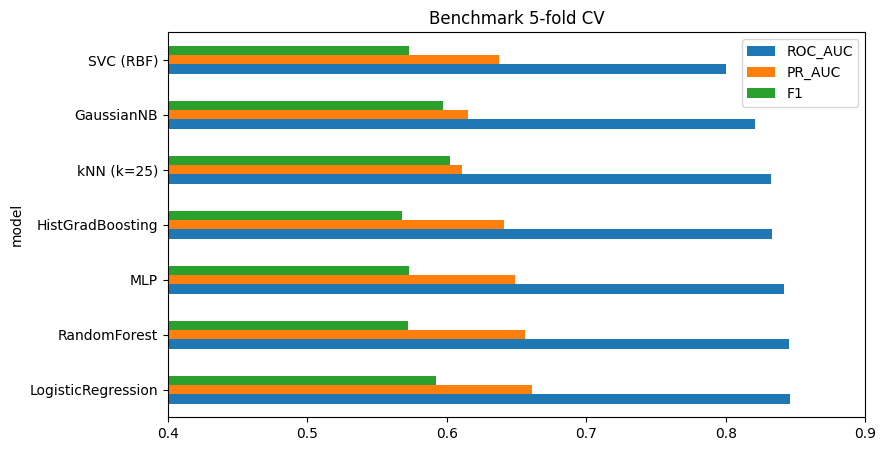

In [ ]:
bench_df.set_index("model")[["ROC_AUC", "PR_AUC", "F1"]].plot(kind="barh", figsize=(9, 5), xlim=(0.4, 0.9),
                                                             title="Benchmark 5-fold CV")
plt.show()

**🔎 Đọc kết quả:** Với dữ liệu này, **Logistic Regression** – mô hình đơn giản nhất – thường ngang ngửa hoặc tốt hơn các mô hình phức tạp (SVM, MLP, Boosting). Đây đúng là thông điệp của chương: *"bắt đầu bằng mô hình đơn giản, chỉ tăng độ phức tạp khi có lý do"*. Logistic còn có lợi thế: nhanh, dễ giải thích, cho xác suất tốt.

Ta sẽ tune **hai ứng viên**: Logistic Regression (dễ giải thích) và HistGradientBoosting (mạnh trên tabular).

## Bước 5. Tuning bằng GridSearchCV

In [ ]:
grid_lr = GridSearchCV(bench["LogisticRegression"],
                       {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3]},
                       cv=cv, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)

grid_hgb = GridSearchCV(bench["HistGradBoosting"],
                        {"model__learning_rate": [0.03, 0.1], "model__max_depth": [3, 5, None],
                         "model__max_iter": [100, 300], "model__min_samples_leaf": [20, 50]},
                        cv=cv, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)

for name, g in [("LogReg", grid_lr), ("HistGB", grid_hgb)]:
    print(f"{name}: best ROC_AUC CV = {g.best_score_:.4f} | params = {g.best_params_}")

LogReg: best ROC_AUC CV = 0.8463 | params = {'model__C': 3}
HistGB: best ROC_AUC CV = 0.8487 | params = {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__max_iter': 100, 'model__min_samples_leaf': 50}


In [ ]:
final = grid_lr if grid_lr.best_score_ >= grid_hgb.best_score_ - 0.005 else grid_hgb
final_name = "LogisticRegression" if final is grid_lr else "HistGradBoosting"
best_model = final.best_estimator_
print("Mô hình được chọn:", final_name,
      "(ưu tiên Logistic nếu chênh lệch AUC < 0.005 vì dễ giải thích hơn)")

Mô hình được chọn: LogisticRegression (ưu tiên Logistic nếu chênh lệch AUC < 0.005 vì dễ giải thích hơn)


## Bước 6. Đánh giá cuối trên test set

Test ROC-AUC: 0.842
Test PR-AUC : 0.630


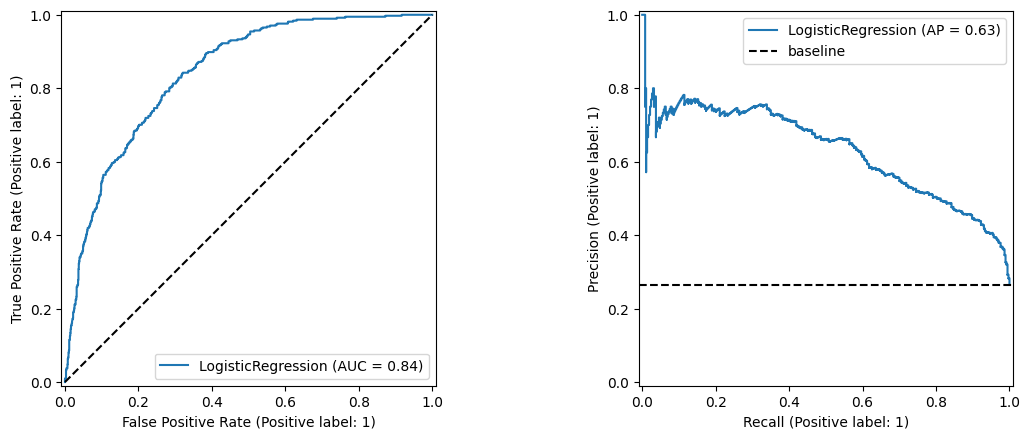

In [ ]:
proba_test = best_model.predict_proba(X_test)[:, 1]
print(f"Test ROC-AUC: {roc_auc_score(y_test, proba_test):.3f}")
print(f"Test PR-AUC : {average_precision_score(y_test, proba_test):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
RocCurveDisplay.from_predictions(y_test, proba_test, ax=ax[0], name=final_name); ax[0].plot([0, 1], [0, 1], "k--")
PrecisionRecallDisplay.from_predictions(y_test, proba_test, ax=ax[1], name=final_name)
ax[1].axhline(y_test.mean(), color="k", ls="--", label="baseline"); ax[1].legend()
plt.tight_layout(); plt.show()

## Bước 7. Chọn ngưỡng theo **lợi nhuận** thay vì 0.5
Lợi nhuận chiến dịch = `150 × TP − 50 × FP`.
💡 **Lý thuyết:** gửi ưu đãi có lợi khi `p × 150 > (1 − p) × 50` ⇔ `p > 50 / (150 + 50) = 0.25`. Nếu xác suất được hiệu chỉnh tốt, ngưỡng tối ưu sẽ **gần 0.25** chứ không phải 0.5!

⚠️ Ngưỡng nên được chọn trên dữ liệu **validation** (ở đây dùng dự báo out-of-fold trên train) rồi mới áp dụng cho test.

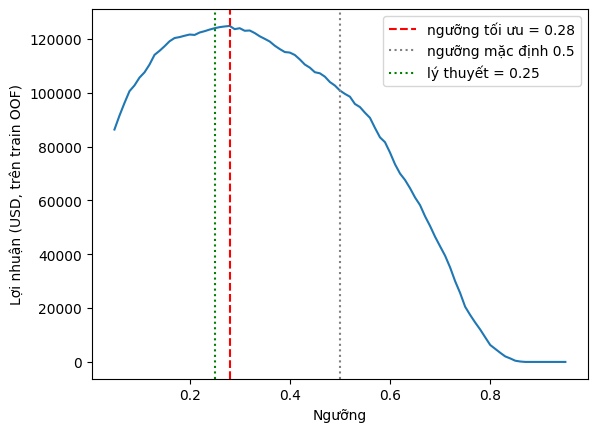

Ngưỡng tối ưu thực nghiệm: 0.28


In [ ]:
from sklearn.model_selection import cross_val_predict
GAIN_TP, COST_FP = 150, 50

oof = cross_val_predict(best_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

def profit(y_true, proba, t):
    pred = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return GAIN_TP * tp - COST_FP * fp, tp, fp, fn

ths = np.arange(0.05, 0.96, 0.01)
profits = [profit(y_train, oof, t)[0] for t in ths]
best_t = ths[int(np.argmax(profits))]

plt.plot(ths, profits); plt.axvline(best_t, color="r", ls="--", label=f"ngưỡng tối ưu = {best_t:.2f}")
plt.axvline(0.5, color="gray", ls=":", label="ngưỡng mặc định 0.5")
plt.axvline(COST_FP/(GAIN_TP+COST_FP), color="g", ls=":", label="lý thuyết = 0.25")
plt.xlabel("Ngưỡng"); plt.ylabel("Lợi nhuận (USD, trên train OOF)"); plt.legend(); plt.show()
print(f"Ngưỡng tối ưu thực nghiệm: {best_t:.2f}")

In [ ]:
rows = []
for t in [0.5, best_t]:
    p, tp, fp, fn = profit(y_test, proba_test, t)
    rows.append({"threshold": round(t, 2), "TP (giữ được)": tp, "FP (gửi nhầm)": fp,
                 "FN (bỏ sót)": fn, "Lợi nhuận test (USD)": p})
pd.DataFrame(rows)

,threshold,TP (giữ được),FP (gửi nhầm),FN (bỏ sót),Lợi nhuận test (USD)
0,0.50,211,108,163,26250
1,0.28,288,272,86,29600


              precision    recall  f1-score   support

       Ở lại       0.90      0.74      0.81      1035
      Rời bỏ       0.51      0.77      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.80      0.75      0.76      1409



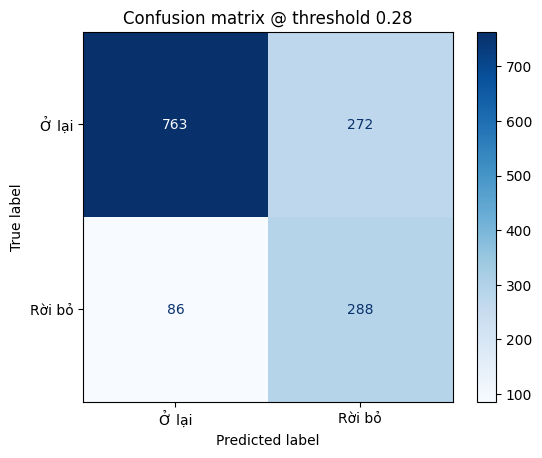

In [ ]:
pred_best = (proba_test >= best_t).astype(int)
print(classification_report(y_test, pred_best, target_names=["Ở lại", "Rời bỏ"]))
ConfusionMatrixDisplay.from_predictions(y_test, pred_best, display_labels=["Ở lại", "Rời bỏ"], cmap="Blues")
plt.title(f"Confusion matrix @ threshold {best_t:.2f}"); plt.show()

## Bước 8. Giải thích mô hình – yếu tố nào dẫn tới churn?

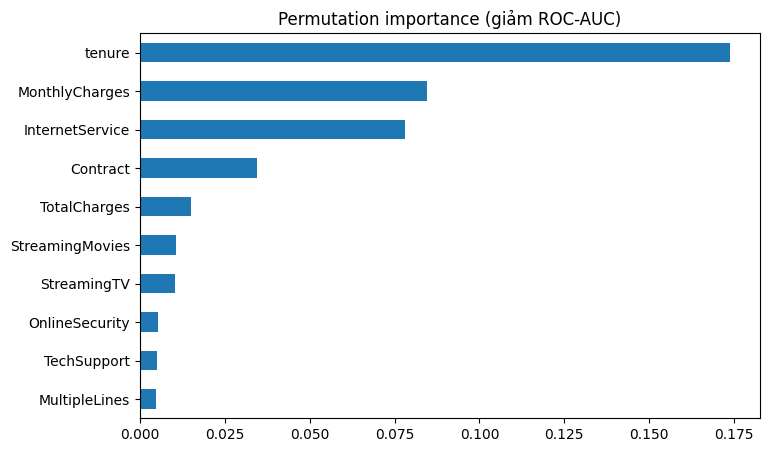

In [ ]:
perm = permutation_importance(best_model, X_test, y_test, scoring="roc_auc",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
imp.tail(10).plot(kind="barh", figsize=(8, 5), title="Permutation importance (giảm ROC-AUC)")
plt.show()

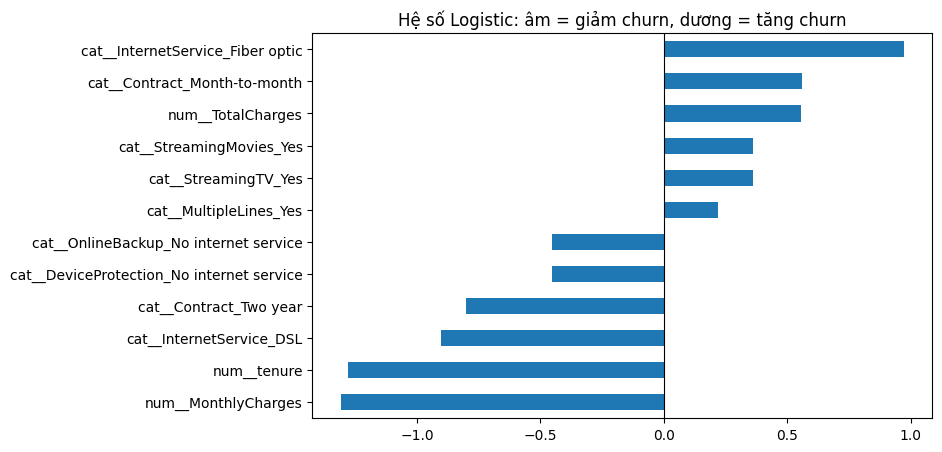

In [ ]:
if final_name == "LogisticRegression":
    names = best_model.named_steps["prep"].get_feature_names_out()
    coef = pd.Series(best_model.named_steps["model"].coef_[0], index=names).sort_values()
    pd.concat([coef.head(6), coef.tail(6)]).plot(kind="barh", figsize=(8, 5),
        title="Hệ số Logistic: âm = giảm churn, dương = tăng churn")
    plt.axvline(0, color="k", lw=.8); plt.show()

## Bước 9. Lưu mô hình và dự báo cho khách hàng mới
Pipeline lưu cả tiền xử lý + mô hình → đưa thẳng dữ liệu thô vào là dự báo được.

In [ ]:
joblib.dump({"model": best_model, "threshold": float(best_t)}, "churn_model.joblib")

bundle = joblib.load("churn_model.joblib")
new_customers = X_test.head(5).copy()
new_customers["churn_proba"] = bundle["model"].predict_proba(new_customers)[:, 1].round(3)
new_customers["gửi_ưu_đãi"] = new_customers["churn_proba"] >= bundle["threshold"]
new_customers[["tenure", "Contract", "InternetService", "MonthlyCharges", "churn_proba", "gửi_ưu_đãi"]]

,tenure,Contract,InternetService,MonthlyCharges,churn_proba,gửi_ưu_đãi
437,72,Two year,Fiber optic,114.05,0.047,False
2280,8,Month-to-month,Fiber optic,100.15,0.683,True
2235,41,One year,DSL,78.35,0.054,False
4460,18,Month-to-month,Fiber optic,78.20,0.412,True
3761,72,Two year,DSL,82.65,0.022,False


> 💾 Trên Colab, tải file mô hình về máy bằng: `from google.colab import files; files.download('churn_model.joblib')`

## Bước 10. Model Card (mẫu – sinh viên hoàn thiện)
| Mục | Nội dung |
|---|---|
| **Mục đích** | Xếp hạng khách hàng theo nguy cơ rời bỏ để ưu tiên chiến dịch giữ chân. *Không* dùng để từ chối dịch vụ. |
| **Dữ liệu** | IBM Telco Churn, 7.043 khách hàng, một thời điểm (snapshot), dữ liệu mẫu công khai. |
| **Mô hình** | *(điền mô hình được chọn + tham số)* |
| **Hiệu năng test** | ROC-AUC = …, PR-AUC = …, lợi nhuận ước tính tại ngưỡng … |
| **Giới hạn** | Giả định chi phí/lợi ích là giả lập; dữ liệu không có yếu tố thời gian → cần *time-based split* khi triển khai thật; phân bố khách có thể thay đổi (data drift). |
| **Rủi ro đạo đức** | Các biến `gender`, `SeniorCitizen` – cần kiểm tra mô hình có đối xử khác biệt giữa các nhóm không. |
| **Giám sát** | Theo dõi AUC và tỷ lệ churn hàng tháng; huấn luyện lại khi hiệu năng giảm. |

## 📝 Bài tập nộp (Lab 6 – bài nhóm)
1. Kiểm tra **fairness**: tính recall của mô hình riêng cho nhóm `SeniorCitizen = 0` và `= 1`. Có chênh lệch không?
2. Thêm `class_weight="balanced"` cho Logistic Regression và chạy lại Bước 7. Ngưỡng tối ưu dịch chuyển thế nào? Vì sao?
3. Bỏ biến `gender` khỏi mô hình. Hiệu năng thay đổi thế nào? Có nên giữ biến này không?
4. Thay đổi giả định: CLV = 300 USD, chi phí ưu đãi = 80 USD. Ngưỡng tối ưu thay đổi ra sao?
5. Thêm **XGBoost** hoặc **LightGBM** (`pip install xgboost lightgbm`) vào benchmark.
6. Hoàn thiện **model card** và viết 1 slide trình bày khuyến nghị cho Giám đốc Marketing.

## YÊU CẦU 1 — Fairness theo `SeniorCitizen`
Tính recall của lớp churn riêng cho `SeniorCitizen = 0` và `= 1` tại ngưỡng chiến dịch `best_t`.

In [ ]:
from sklearn.metrics import recall_score

def group_recall_table(group_values, y_true, y_pred, group_name):
    rows = []
    gvals, yt, yp = np.asarray(group_values), np.asarray(y_true), np.asarray(y_pred)
    for g in sorted(pd.Series(gvals).dropna().unique()):
        mask = gvals == g
        rows.append({
            group_name: g, "n_test": int(mask.sum()), "actual_churn": int(yt[mask].sum()),
            "predicted_churn": int(yp[mask].sum()),
            "recall": recall_score(yt[mask], yp[mask], zero_division=0)
        })
    return pd.DataFrame(rows)

fair_senior = group_recall_table(X_test["SeniorCitizen"].values, y_test.values, pred_best, "SeniorCitizen")
rec0 = float(fair_senior.loc[fair_senior["SeniorCitizen"] == 0, "recall"].iloc[0])
rec1 = float(fair_senior.loc[fair_senior["SeniorCitizen"] == 1, "recall"].iloc[0])
senior_recall_gap = abs(rec1 - rec0)
print(f"Threshold fairness: {best_t:.2f}")
display(fair_senior.style.format({"recall":"{:.3f}"}))
print(f"Recall gap tuyệt đối = {senior_recall_gap:.3f} ({senior_recall_gap*100:.1f} điểm %)")

Threshold fairness: 0.28


,SeniorCitizen,n_test,actual_churn,predicted_churn,recall
0,0,1187,276,414,0.725
1,1,222,98,146,0.898


Recall gap tuyệt đối = 0.173 (17.3 điểm %)


## YÊU CẦU 2 — `class_weight="balanced"` cho Logistic Regression
Giữ cùng `C` tốt nhất, chỉ thêm `class_weight="balanced"`, rồi chọn lại threshold bằng cùng hàm lợi nhuận. Bổ sung Brier score để đánh giá calibration.

In [ ]:
from sklearn.base import clone
from sklearn.metrics import brier_score_loss

best_C = grid_lr.best_params_["model__C"]
lr_unweighted = grid_lr.best_estimator_
lr_balanced = make(LogisticRegression(C=best_C, class_weight="balanced", max_iter=2000))

def choose_profit_threshold(model, Xtr, ytr, gain_tp=150, cost_fp=50):
    proba_oof = cross_val_predict(model, Xtr, ytr, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    grid = np.arange(0.05, 0.96, 0.01)
    vals = []
    for t in grid:
        pred = (proba_oof >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(ytr, pred).ravel()
        vals.append(gain_tp*tp - cost_fp*fp)
    return float(grid[int(np.argmax(vals))]), proba_oof, max(vals)

t_lr, oof_lr, _ = choose_profit_threshold(lr_unweighted, X_train, y_train)
t_bal, oof_bal, _ = choose_profit_threshold(lr_balanced, X_train, y_train)

lr_unweighted_fit = clone(lr_unweighted).fit(X_train, y_train)
lr_balanced_fit = clone(lr_balanced).fit(X_train, y_train)
p_lr = lr_unweighted_fit.predict_proba(X_test)[:, 1]
p_bal = lr_balanced_fit.predict_proba(X_test)[:, 1]

def model_row(label, p, threshold):
    pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {"Mô hình":label, "C":best_C, "Ngưỡng tối ưu OOF":threshold,
            "ROC-AUC test":roc_auc_score(y_test,p), "PR-AUC test":average_precision_score(y_test,p),
            "Brier score":brier_score_loss(y_test,p), "Mean predicted p":p.mean(),
            "TP":tp, "FP":fp, "FN":fn, "Recall@opt":recall_score(y_test,pred),
            "Profit test (USD)":150*tp-50*fp}

class_weight_compare = pd.DataFrame([
    model_row("Logistic thường", p_lr, t_lr),
    model_row('Logistic class_weight="balanced"', p_bal, t_bal)
])
display(class_weight_compare.style.format({
    "Ngưỡng tối ưu OOF":"{:.2f}", "ROC-AUC test":"{:.4f}", "PR-AUC test":"{:.4f}",
    "Brier score":"{:.4f}", "Mean predicted p":"{:.4f}", "Recall@opt":"{:.4f}"
}))
print(f"Threshold dịch {t_lr:.2f} -> {t_bal:.2f}.")

,Mô hình,C,Ngưỡng tối ưu OOF,ROC-AUC test,PR-AUC test,Brier score,Mean predicted p,TP,FP,FN,Recall@opt,Profit test (USD)
0,Logistic thường,3,0.28,0.8417,0.6299,0.1383,0.2679,288,272,86,0.7701,29600
1,"Logistic class_weight=""balanced""",3,0.50,0.8410,0.6287,0.1690,0.4157,293,283,81,0.7834,29800


Threshold dịch 0.28 -> 0.50.


## YÊU CẦU 3 — Bỏ biến `gender`
Tạo Pipeline mới không có `gender`, giữ Logistic Regression và `C` tốt nhất; so sánh ROC-AUC, PR-AUC, F1, threshold và profit.

In [ ]:
X_train_no_gender = X_train.drop(columns="gender")
X_test_no_gender = X_test.drop(columns="gender")
cat_cols_no_gender = [c for c in X_train_no_gender.columns if c not in num_cols]

preprocess_no_gender = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols_no_gender),
])
lr_no_gender = Pipeline([
    ("prep", preprocess_no_gender),
    ("model", LogisticRegression(C=best_C, max_iter=2000))
])

t_no_gender, oof_no_gender, _ = choose_profit_threshold(lr_no_gender, X_train_no_gender, y_train)
lr_no_gender_fit = clone(lr_no_gender).fit(X_train_no_gender, y_train)
p_no_gender = lr_no_gender_fit.predict_proba(X_test_no_gender)[:, 1]

def perf_row(label, p, threshold):
    pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {"Trường hợp":label, "Threshold OOF":threshold, "ROC-AUC":roc_auc_score(y_test,p),
            "PR-AUC":average_precision_score(y_test,p), "F1@0.5":f1_score(y_test,(p>=0.5).astype(int)),
            "Recall@opt":recall_score(y_test,pred), "TP":tp, "FP":fp, "FN":fn,
            "Profit@opt (USD)":150*tp-50*fp}

gender_drop_compare = pd.DataFrame([
    perf_row("Có gender", p_lr, t_lr),
    perf_row("Bỏ gender", p_no_gender, t_no_gender)
])
display(gender_drop_compare.style.format({
    "Threshold OOF":"{:.2f}", "ROC-AUC":"{:.4f}", "PR-AUC":"{:.4f}",
    "F1@0.5":"{:.4f}", "Recall@opt":"{:.4f}"
}))

pred_lr_opt = (p_lr >= t_lr).astype(int)
fair_gender = group_recall_table(X_test["gender"].values, y_test.values, pred_lr_opt, "gender")
display(fair_gender.style.format({"recall":"{:.3f}"}))

,Trường hợp,Threshold OOF,ROC-AUC,PR-AUC,F1@0.5,Recall@opt,TP,FP,FN,Profit@opt (USD)
0,Có gender,0.28,0.8417,0.6299,0.6089,0.7701,288,272,86,29600
1,Bỏ gender,0.27,0.8419,0.6308,0.6029,0.7807,292,278,82,29900


,gender,n_test,actual_churn,predicted_churn,recall
0,Female,687,193,272,0.762
1,Male,722,181,288,0.779


## YÊU CẦU 4 — CLV = 300 USD, chi phí ưu đãi = 80 USD
Giữ tỷ lệ chấp nhận 40%. Lợi ích kỳ vọng của TP là `0.4×300 − 80 = +40 USD`; FP tốn `80 USD`. Ước lượng lại threshold trên OOF train.

In [ ]:
NEW_CLV = 300
NEW_OFFER_COST = 80
ACCEPT_RATE = 0.40
NEW_GAIN_TP = ACCEPT_RATE*NEW_CLV - NEW_OFFER_COST
NEW_COST_FP = NEW_OFFER_COST
new_theoretical_t = NEW_COST_FP/(NEW_GAIN_TP + NEW_COST_FP)

grid_new = np.arange(0.05,0.96,0.01)
new_profit_train = []
for t in grid_new:
    pred = (oof >= t).astype(int)
    tn,fp,fn,tp = confusion_matrix(y_train,pred).ravel()
    new_profit_train.append(NEW_GAIN_TP*tp - NEW_COST_FP*fp)
new_best_t = float(grid_new[int(np.argmax(new_profit_train))])

def new_econ_row(t):
    pred = (proba_test >= t).astype(int)
    tn,fp,fn,tp = confusion_matrix(y_test,pred).ravel()
    return {"Threshold":t,"TP":tp,"FP":fp,"FN":fn,
            "Profit mới (USD)":NEW_GAIN_TP*tp-NEW_COST_FP*fp}

new_econ_compare = pd.DataFrame([
    new_econ_row(0.5), new_econ_row(best_t), new_econ_row(new_best_t)
]).drop_duplicates("Threshold").sort_values("Threshold")
print(f"TP gain mới = {NEW_GAIN_TP:.0f} USD; FP cost = {NEW_COST_FP:.0f} USD")
print(f"Threshold lý thuyết = {new_theoretical_t:.3f}; threshold OOF thực nghiệm = {new_best_t:.2f}")
display(new_econ_compare.style.format({"Threshold":"{:.2f}"}))

TP gain mới = 40 USD; FP cost = 80 USD
Threshold lý thuyết = 0.667; threshold OOF thực nghiệm = 0.68


,Threshold,TP,FP,FN,Profit mới (USD)
1,0.28,288,272,86,-10240.000000
0,0.50,211,108,163,-200.000000
2,0.68,87,33,287,840.000000


## YÊU CẦU 5 — Thêm XGBoost vào benchmark
XGBoost được thêm như một mô hình mới, dùng cùng Pipeline và cùng 5-fold Stratified CV; benchmark gốc không bị sửa.

In [ ]:
from xgboost import XGBClassifier

xgb_pipe = make(XGBClassifier(
    n_estimators=400, learning_rate=0.05, max_depth=3, min_child_weight=2,
    subsample=0.85, colsample_bytree=0.85, reg_lambda=1.0,
    objective="binary:logistic", eval_metric="logloss",
    random_state=RANDOM_STATE, n_jobs=1
))
t0 = time.time()
xgb_cv = cross_validate(xgb_pipe, X_train, y_train, cv=cv, n_jobs=-1,
    scoring={"roc_auc":"roc_auc","pr_auc":"average_precision","f1":"f1"})
xgb_row = pd.DataFrame([{
    "model":"XGBoost", "ROC_AUC":xgb_cv["test_roc_auc"].mean(),
    "ROC_AUC_std":xgb_cv["test_roc_auc"].std(), "PR_AUC":xgb_cv["test_pr_auc"].mean(),
    "F1":xgb_cv["test_f1"].mean(), "time_s":time.time()-t0
}])
benchmark_with_xgb = pd.concat([bench_df,xgb_row],ignore_index=True).sort_values("ROC_AUC",ascending=False)
display(benchmark_with_xgb.style.format({
    "ROC_AUC":"{:.4f}","ROC_AUC_std":"{:.4f}","PR_AUC":"{:.4f}","F1":"{:.4f}","time_s":"{:.2f}"
}))

,model,ROC_AUC,ROC_AUC_std,PR_AUC,F1,time_s
0,LogisticRegression,0.8460,0.0130,0.6610,0.5920,2.66
1,RandomForest,0.8450,0.0090,0.6560,0.5720,2.33
7,XGBoost,0.8447,0.0108,0.6638,0.5855,0.64
2,MLP,0.8420,0.0120,0.6490,0.5730,0.41
3,HistGradBoosting,0.8330,0.0060,0.6410,0.5680,1.51
4,kNN (k=25),0.8320,0.0080,0.6110,0.6020,0.20
5,GaussianNB,0.8210,0.0120,0.6150,0.5970,0.11
6,SVC (RBF),0.8000,0.0160,0.6370,0.5730,1.54


## YÊU CẦU 6 — Hoàn thiện Model Card và nội dung 1 slide khuyến nghị
Model Card dùng kết quả thực tế, không để placeholder; phần slide tập trung vào quyết định Marketing, giá trị kinh doanh và guardrails.

In [ ]:
from IPython.display import Markdown, display as ipy_display

model_test_auc = roc_auc_score(y_test, proba_test)
model_test_prauc = average_precision_score(y_test, proba_test)
profit_opt, tp_opt, fp_opt, fn_opt = profit(y_test, proba_test, best_t)
profit_05, tp05, fp05, fn05 = profit(y_test, proba_test, 0.5)
top5_features = imp.sort_values(ascending=False).head(5)
top5_text = ", ".join([f"{k} ({v:.4f})" for k,v in top5_features.items()])

model_card = pd.DataFrame([
["Mục đích","Xếp hạng khách hàng theo nguy cơ churn để ưu tiên chiến dịch giữ chân; không dùng để từ chối dịch vụ."],
["Dữ liệu",f"IBM Telco Customer Churn: {len(df):,} khách hàng; target Churn; snapshot, không có trục thời gian."],
["Mô hình",f"{final_name}; best params: {final.best_params_}"],
["Hiệu năng test",f"ROC-AUC={model_test_auc:.3f}; PR-AUC={model_test_prauc:.3f}."],
["Ngưỡng kinh doanh",f"Threshold OOF={best_t:.2f}; profit test=${profit_opt:,.0f} so với ${profit_05:,.0f} tại 0.50."],
["Fairness",f"SeniorCitizen recall gap={senior_recall_gap*100:.1f} điểm % tại threshold {best_t:.2f}; cần theo dõi định kỳ."],
["Yếu tố quan trọng",top5_text],
["Giới hạn","Dữ liệu mẫu công khai, snapshot; giả định CLV/chi phí là mô phỏng; chưa phản ánh time drift và causal uplift."],
["Rủi ro đạo đức","Có biến nhân khẩu học nhạy cảm; cần kiểm tra chênh lệch hiệu năng giữa nhóm và tránh dùng dự báo để hạn chế quyền lợi."],
["Giám sát","Theo dõi ROC-AUC/PR-AUC, calibration, churn rate, profit thực tế và fairness gap; cập nhật threshold khi economics/data drift thay đổi."]
],columns=["Mục","Nội dung"])
display(model_card)

slide_md = f"""
### 1 SLIDE — KHUYẾN NGHỊ CHO GIÁM ĐỐC MARKETING
- **Mô hình:** {final_name}; Test ROC-AUC **{model_test_auc:.3f}**, PR-AUC **{model_test_prauc:.3f}**.
- **Ngưỡng hành động:** **{best_t:.2f}** từ OOF train, thay vì 0.50.
- **Lợi nhuận mô phỏng test:** **${profit_opt:,.0f}** vs **${profit_05:,.0f}** tại 0.50.
- **Top drivers:** **{', '.join(top5_features.index[:3])}**.
- **Guardrails:** calibration, fairness SeniorCitizen/gender, data drift, cập nhật threshold khi economics thay đổi.
- **Triển khai:** pilot A/B và đo incremental retention/uplift + profit thực tế trước rollout.
"""
ipy_display(Markdown(slide_md))

,Mục,Nội dung
0,Mục đích,Xếp hạng khách hàng theo nguy cơ churn để ưu t...
1,Dữ liệu,"IBM Telco Customer Churn: 7,043 khách hàng; ta..."
2,Mô hình,LogisticRegression; best params: {'model__C': 3}
3,Hiệu năng test,ROC-AUC=0.842; PR-AUC=0.630.
4,Ngưỡng kinh doanh,"Threshold OOF=0.28; profit test=$29,600 so với..."
5,Fairness,SeniorCitizen recall gap=17.3 điểm % tại thres...
6,Yếu tố quan trọng,"tenure (0.1739), MonthlyCharges (0.0847), Inte..."
7,Giới hạn,"Dữ liệu mẫu công khai, snapshot; giả định CLV/..."
8,Rủi ro đạo đức,Có biến nhân khẩu học nhạy cảm; cần kiểm tra c...
9,Giám sát,"Theo dõi ROC-AUC/PR-AUC, calibration, churn ra..."



### 1 SLIDE — KHUYẾN NGHỊ CHO GIÁM ĐỐC MARKETING
- **Mô hình:** LogisticRegression; Test ROC-AUC **0.842**, PR-AUC **0.630**.
- **Ngưỡng hành động:** **0.28** từ OOF train, thay vì 0.50.
- **Lợi nhuận mô phỏng test:** **$29,600** vs **$26,250** tại 0.50.
- **Top drivers:** **tenure, MonthlyCharges, InternetService**.
- **Guardrails:** calibration, fairness SeniorCitizen/gender, data drift, cập nhật threshold khi economics thay đổi.
- **Triển khai:** pilot A/B và đo incremental retention/uplift + profit thực tế trước rollout.


## KẾT LUẬN 6 YÊU CẦU
Xuất bảng tổng hợp và file JSON dùng để viết báo cáo Word.

In [ ]:
summary_table = pd.DataFrame([
["1. Fairness SeniorCitizen",f"Recall gap={senior_recall_gap:.3f} ({senior_recall_gap*100:.1f} điểm %)."],
["2. class_weight=balanced",f"Threshold Logistic {t_lr:.2f}->{t_bal:.2f}; Brier {brier_score_loss(y_test,p_lr):.4f}->{brier_score_loss(y_test,p_bal):.4f}."],
["3. Bỏ gender",f"ROC-AUC {roc_auc_score(y_test,p_lr):.4f}->{roc_auc_score(y_test,p_no_gender):.4f}; threshold={t_no_gender:.2f}."],
["4. CLV=300, offer=80",f"TP gain=${NEW_GAIN_TP:.0f}; theoretical={new_theoretical_t:.3f}; OOF best={new_best_t:.2f}."],
["5. XGBoost",f"CV ROC-AUC={xgb_row.iloc[0]['ROC_AUC']:.4f}; PR-AUC={xgb_row.iloc[0]['PR_AUC']:.4f}; F1={xgb_row.iloc[0]['F1']:.4f}."],
["6. Model card",f"{final_name}; test ROC-AUC={model_test_auc:.3f}; threshold={best_t:.2f}; profit=${profit_opt:,.0f}."]
],columns=["Yêu cầu","Kết quả chính"])
display(summary_table)

import json
results_for_report = {
"final_name":final_name,"best_params":final.best_params_,
"test_roc_auc":float(model_test_auc),"test_pr_auc":float(model_test_prauc),
"best_t":float(best_t),"profit_opt":int(profit_opt),"profit_05":int(profit_05),
"senior_fairness":fair_senior.to_dict(orient="records"),"senior_recall_gap":float(senior_recall_gap),
"class_weight_compare":class_weight_compare.to_dict(orient="records"),
"gender_drop_compare":gender_drop_compare.to_dict(orient="records"),
"fair_gender":fair_gender.to_dict(orient="records"),
"new_econ":{"gain_tp":float(NEW_GAIN_TP),"cost_fp":float(NEW_COST_FP),"theoretical_t":float(new_theoretical_t),
            "best_t":float(new_best_t),"table":new_econ_compare.to_dict(orient="records")},
"xgb":xgb_row.to_dict(orient="records")[0],
"benchmark_with_xgb":benchmark_with_xgb.to_dict(orient="records"),
"top_features":{str(k):float(v) for k,v in top5_features.items()}
}
with open("DS6_results_for_report.json","w",encoding="utf-8") as f:
    json.dump(results_for_report,f,ensure_ascii=False,indent=2)
print("Đã lưu DS6_results_for_report.json")

,Yêu cầu,Kết quả chính
0,1. Fairness SeniorCitizen,Recall gap=0.173 (17.3 điểm %).
1,2. class_weight=balanced,Threshold Logistic 0.28->0.50; Brier 0.1383->0...
2,3. Bỏ gender,ROC-AUC 0.8417->0.8419; threshold=0.27.
3,"4. CLV=300, offer=80",TP gain=$40; theoretical=0.667; OOF best=0.68.
4,5. XGBoost,CV ROC-AUC=0.8447; PR-AUC=0.6638; F1=0.5855.
5,6. Model card,LogisticRegression; test ROC-AUC=0.842; thresh...


Đã lưu DS6_results_for_report.json
